<a href="https://colab.research.google.com/github/CooL-Legend/CSCI544-DLM/blob/main/notebooks/LLaDA_Sudoku_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LLaDA Sudoku on Colab Pro

Run the GitHub project with a persistent model copy in Google Drive. Choose **Runtime → Change runtime type → GPU → L4 or A100** (subject to availability), then run the cells in order. Start with one puzzle.

The first session downloads about 16 GB of weights to Drive. Later sessions reuse those files. Each fresh runtime still needs to read the weights into GPU memory. The optional copy to `/content` speeds repeated model loads within a session; it uses runtime disk space, not another Drive copy.

For this **private GitHub repository**, open the notebook through Colab's GitHub tab after authorizing GitHub, or upload this `.ipynb` file to Colab. The clone cell separately needs a fine-grained GitHub token with **Contents: read** access to this repository. Store it in Colab **Secrets** as `GITHUB_TOKEN` and allow notebook access, or enter it into the hidden prompt. The token is never written to the clone URL, repository, or notebook output.


In [1]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Select an L4 or A100 GPU runtime, then reconnect.")
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name} | GPU memory: {gpu.total_memory / 2**30:.1f} GiB")
if gpu.total_memory < 20 * 2**30:
    raise RuntimeError("This notebook uses unquantized BF16 weights. Choose an L4/A100 runtime with more GPU memory; a 16 GB T4 is too small for this setup.")
if not torch.cuda.is_bf16_supported():
    raise RuntimeError("This GPU does not support the configured BF16 inference.")


GPU: NVIDIA L4 | GPU memory: 22.0 GiB


## 1. Get the code from GitHub
This cell clones the repository, or updates an existing clean checkout without discarding changes.


In [2]:
from pathlib import Path
import getpass
import os
import subprocess
import sys
import tempfile

REPOSITORY = "CooL-Legend/CSCI544-DLM"
BRANCH = "main"
REPO_URL = f"https://github.com/{REPOSITORY}.git"
REPO_DIR = Path("/content/CSCI544-DLM")

if REPO_DIR.exists():
    if not (REPO_DIR / ".git").is_dir():
        raise RuntimeError(f"{REPO_DIR} exists but is not a Git checkout. Choose another REPO_DIR.")
    existing_url = subprocess.check_output(["git", "-C", str(REPO_DIR), "remote", "get-url", "origin"], text=True).strip()
    if existing_url != REPO_URL:
        raise RuntimeError("The existing checkout belongs to a different repository.")
    git_args = ["-C", str(REPO_DIR), "pull", "--ff-only", "origin", BRANCH]
else:
    git_args = ["clone", "--branch", BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)]

def run_git(token=None):
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    with tempfile.TemporaryDirectory() as tmp:
        if token:
            askpass = Path(tmp) / "askpass.py"
            askpass.write_text(
                "#!/usr/bin/env python3\nimport os, sys\n"
                "print('x-access-token' if 'username' in sys.argv[1].lower() else os.environ['COLAB_GH_TOKEN'])\n"
            )
            askpass.chmod(0o700)
            env.update(GIT_ASKPASS=str(askpass), COLAB_GH_TOKEN=token)
        return subprocess.run(["git", "-c", "credential.helper=", *git_args], env=env, capture_output=True, text=True)

result = run_git()
if result.returncode:
    from google.colab import userdata
    try:
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        token = None
    if not token:
        token = getpass.getpass("GitHub token with read access to this private repository: ")
    try:
        result = run_git(token)
    finally:
        del token
if result.returncode:
    raise RuntimeError(result.stderr.strip() or "GitHub clone/update failed.")
print(f"Code ready: {REPO_DIR}")
print("Commit:", subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"], text=True).strip())


GitHub token with read access to this private repository: ··········
Code ready: /content/CSCI544-DLM
Commit: 3979df4


## 2. Install dependencies
Keep Colab’s CUDA-enabled PyTorch. Model execution uses a fresh Python process so it sees these installed package versions.


In [3]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO_DIR / "requirements-colab.txt")], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', '/content/CSCI544-DLM/requirements-colab.txt'], returncode=0)

## 3. Mount Drive and choose the run size
Keep at least **20 GB of free Google Drive storage** for the model and dataset, with extra room for results. Colab Pro and Drive storage are separate allowances. Start with `NUM_SAMPLES = 1`, then try 10 or 100.

Set `COPY_MODEL_TO_RUNTIME = False` to load directly from Drive. The default keeps the persistent copy on Drive and stages model files on the runtime disk for loading.


In [4]:
from google.colab import drive

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/CSCI544-DLM")
DRIVE_MODEL_DIR = DRIVE_ROOT / "models/LLaDA-8B-Instruct"
RUNTIME_MODEL_DIR = Path("/content/models/LLaDA-8B-Instruct")
COPY_MODEL_TO_RUNTIME = True
NUM_SAMPLES = 1

DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
os.environ["HF_HUB_CACHE"] = str(DRIVE_ROOT / "cache/hub")
os.environ["HF_DATASETS_CACHE"] = str(DRIVE_ROOT / "cache/datasets")
MODEL_PATH = RUNTIME_MODEL_DIR if COPY_MODEL_TO_RUNTIME else DRIVE_MODEL_DIR
print("Persistent files:", DRIVE_ROOT)


Mounted at /content/drive
Persistent files: /content/drive/MyDrive/CSCI544-DLM


## 4. Check the data and write this run’s configuration
The first dataset preparation may process all one million rows before selecting your requested sample. The CSV columns are explicitly strings to preserve leading zeros.


In [5]:
import yaml

config = yaml.safe_load((REPO_DIR / "configs/sudoku.yaml").read_text())
config["data"].update(num_samples=NUM_SAMPLES, cache_dir=os.environ["HF_DATASETS_CACHE"])
config["model"].update(model_path=str(MODEL_PATH), device="cuda", local_files_only=True)
config["output_dir"] = str(DRIVE_ROOT / "results")
config["provenance"] = {
    "git_commit": subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip(),
    "model_revision": "08b83a6feb34df1a6011b80c3c00c7563e963b07",
}
RUN_CONFIG = Path("/content/sudoku-run.yaml")
RUN_CONFIG.write_text(yaml.safe_dump(config, sort_keys=False))
subprocess.run([sys.executable, "-u", str(REPO_DIR / "Llada-Sudoku/run_sudoku.py"), "--config", str(RUN_CONFIG), "--dataset-only"], check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/CSCI544-DLM/Llada-Sudoku/run_sudoku.py', '--config', '/content/sudoku-run.yaml', '--dataset-only'], returncode=0)

## 5. Cache the model on Drive
Download the tokenizer, model configuration, Python model implementation, and all six weight shards. A fixed model revision keeps experiments consistent. Hugging Face checks its download metadata and reuses unchanged files on subsequent sessions; keep the model directory's hidden `.cache` folder.

If a download is interrupted, rerun this cell. If it reports a missing file or Drive quota problem, resolve that before proceeding. No model weights are committed to GitHub.


In [6]:
command = [sys.executable, "-u", str(REPO_DIR / "scripts/cache_model.py"), "--drive-dir", str(DRIVE_MODEL_DIR)]
if COPY_MODEL_TO_RUNTIME:
    command += ["--runtime-dir", str(RUNTIME_MODEL_DIR)]
subprocess.run(command, check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/CSCI544-DLM/scripts/cache_model.py', '--drive-dir', '/content/drive/MyDrive/CSCI544-DLM/models/LLaDA-8B-Instruct', '--runtime-dir', '/content/models/LLaDA-8B-Instruct'], returncode=0)

## 6. Run the experiment
The model loads onto the GPU once per invocation. Predictions are appended to Drive after each puzzle, and metrics are updated as the run progresses. Each invocation creates a new timestamped result directory. Interrupted runs retain completed predictions; automatic resume is not implemented.

To change the sample count or generation settings, update the variables/configuration above and rerun the configuration cell before this cell.


In [7]:
subprocess.run([sys.executable, "-u", str(REPO_DIR / "Llada-Sudoku/run_sudoku.py"), "--config", str(RUN_CONFIG)], check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/CSCI544-DLM/Llada-Sudoku/run_sudoku.py', '--config', '/content/sudoku-run.yaml'], returncode=0)

## 7. Inspect the latest saved results


In [8]:
import json

runs = sorted(path for path in (DRIVE_ROOT / "results").glob("*") if (path / "metrics.json").is_file())
if not runs:
    raise RuntimeError("No saved runs found yet.")
latest = runs[-1]
print("Results:", latest)
print(json.dumps(json.loads((latest / "metrics.json").read_text()), indent=2))
with (latest / "predictions.jsonl").open() as handle:
    first_record = handle.readline()
if first_record:
    print("First prediction:")
    print(json.dumps(json.loads(first_record), indent=2))


Results: /content/drive/MyDrive/CSCI544-DLM/results/20260919T223035054987Z
{
  "status": "completed",
  "requested": 1,
  "processed": 1,
  "exact_accuracy": 0.0,
  "cell_accuracy": 0.0
}
First prediction:
{
  "index": 0,
  "puzzle": "009083400005179802823005700107000605200560179604900003971030504000400917000001300",
  "solution": "719283456465179832823645791197328645238564179654917283971832564382456917546791328",
  "num_blanks": 40,
  "raw_output": "5 7 9 8 3 4 6 1\n3 5 1 7 9 8 4 2\n8 2 3 4 5 7 9 6\n1 4 7 9 2 6 3 5\n2 8 5 6 4 1 7 9\n6 1 4 9 7 8 2 3\n9 7 1 3 6 5 8 4\n4 6 2 4 8 9 1 7",
  "prediction": "",
  "exact": false,
  "correct_cells": 0
}


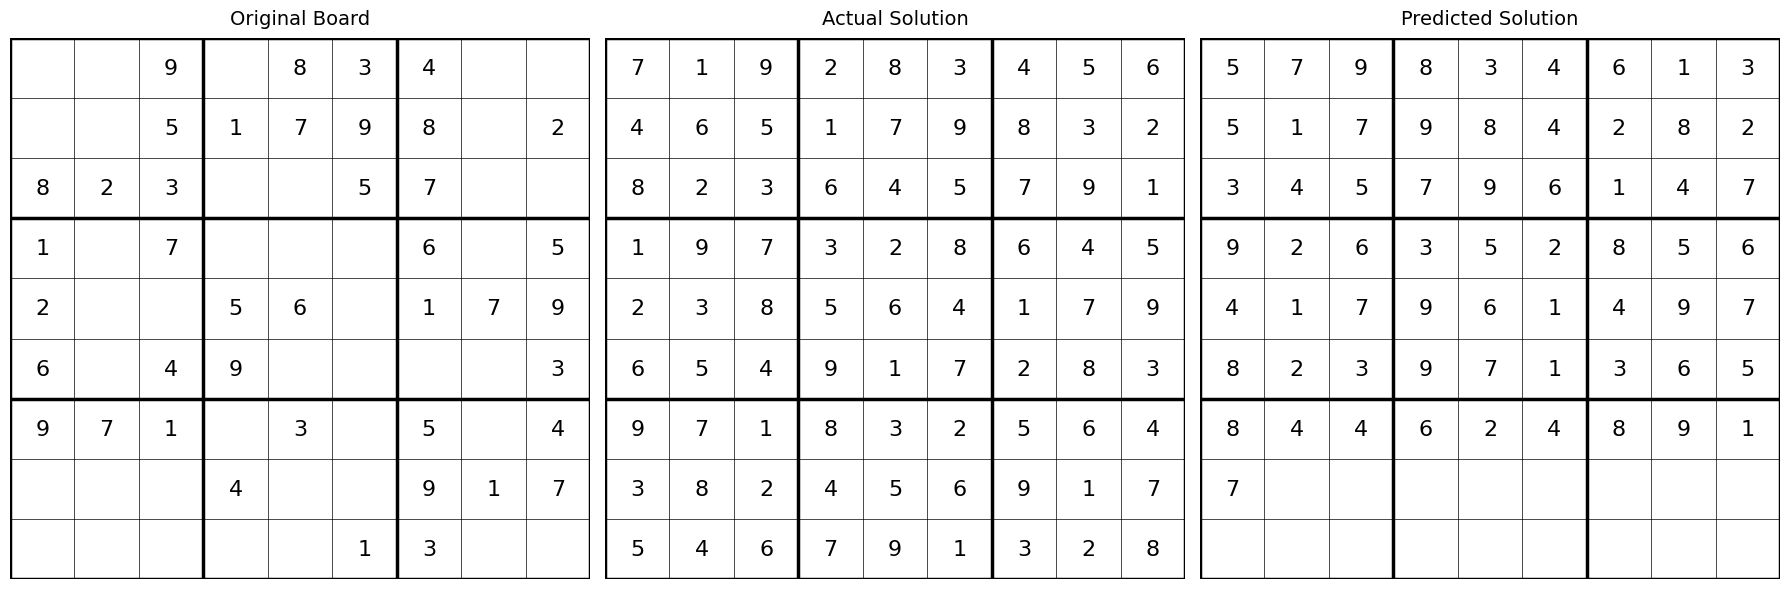

In [9]:
import json
import matplotlib.pyplot as plt

# Load the parsed record from the previous cell
record = json.loads(first_record)

def draw_sudoku(ax, board_str, title):
    ax.set_title(title, fontsize=14, pad=10)
    ax.set_xlim(0, 9)
    ax.set_ylim(0, 9)
    ax.invert_yaxis()
    ax.axis('off')

    # Draw grid lines
    for i in range(10):
        lw = 2.5 if i % 3 == 0 else 0.5
        ax.axhline(i, color='black', linewidth=lw)
        ax.axvline(i, color='black', linewidth=lw)

    # Clean up string and pad with '0' if incomplete
    board_str = board_str.replace(" ", "").replace("\n", "")
    board_str = board_str.ljust(81, '0')

    # Fill the numbers
    for i in range(9):
        for j in range(9):
            idx = i * 9 + j
            if idx < len(board_str):
                val = board_str[idx]
                if val != '0' and val.isdigit():
                    # Differentiate original vs filled numbers could be added here if needed
                    ax.text(j + 0.5, i + 0.5, val, ha='center', va='center', fontsize=16)

# Set up the plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

draw_sudoku(axes[0], record.get('puzzle', ''), "Original Board")
draw_sudoku(axes[1], record.get('solution', ''), "Actual Solution")

# Fallback to raw_output if prediction parser returned empty
pred_str = record.get('prediction', '')
if not pred_str:
    pred_str = record.get('raw_output', '')

draw_sudoku(axes[2], pred_str, "Predicted Solution")

plt.tight_layout()
plt.show()

### Notes and references
- Exact accuracy compares all 81 digits with the dataset solution. Cell accuracy counts matches over all requested cells in completed predictions; outputs with fewer than 81 digits count as zero correct cells.
- The parser retains the original experiment's first-81-digits behavior. This is reference-solution matching, not an independent Sudoku validity check.
- [LLaDA](https://github.com/ML-GSAI/LLaDA) · [Model](https://huggingface.co/GSAI-ML/LLaDA-8B-Instruct) · [Dataset](https://huggingface.co/datasets/certen/Sudoku-1M-Puzzles)
- [Persistent Hugging Face downloads](https://huggingface.co/docs/huggingface_hub/guides/download#download-files-to-a-local-folder) · [Colab resource and storage FAQ](https://research.google.com/colaboratory/faq.html)
